# ANN Classification

## import library

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

## load the data

In [84]:
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

In [85]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [86]:
print("Dataset shape:", df.shape)


Dataset shape: (569, 31)


In [87]:
print("Number of samples:", len(df))

Number of samples: 569


In [88]:
print("Number of features:", len(data.feature_names))

Number of features: 30


In [89]:
print("Number of classes:", df["target"].nunique())

Number of classes: 2


In [90]:
print(df["target"].value_counts())
print(data.target_names)

target
1    357
0    212
Name: count, dtype: int64
['malignant' 'benign']


## Clean the Data

In [91]:
df.isnull().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


In [92]:
df.duplicated().sum()

np.int64(0)

In [93]:
df.dtypes

,0
mean radius,float64
mean texture,float64
mean perimeter,float64
mean area,float64
mean smoothness,float64
mean compactness,float64
mean concavity,float64
mean concave points,float64
mean symmetry,float64
mean fractal dimension,float64


In [94]:
# Check that all features are numerical
df.drop(columns="target").select_dtypes(exclude="number").columns

Index([], dtype='object')

In [95]:
# Check target classes
print(df["target"].value_counts())

target
1    357
0    212
Name: count, dtype: int64


In [96]:
print("Final dataset shape:", df.shape)

Final dataset shape: (569, 31)


## Perform Simple EDA

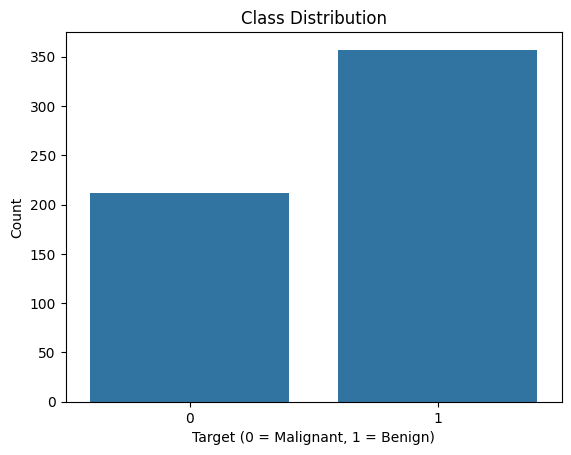

In [97]:
# Class Distribution Plot
sns.countplot(data=df, x="target")
plt.title("Class Distribution")
plt.xlabel("Target (0 = Malignant, 1 = Benign)")
plt.ylabel("Count")
plt.show()

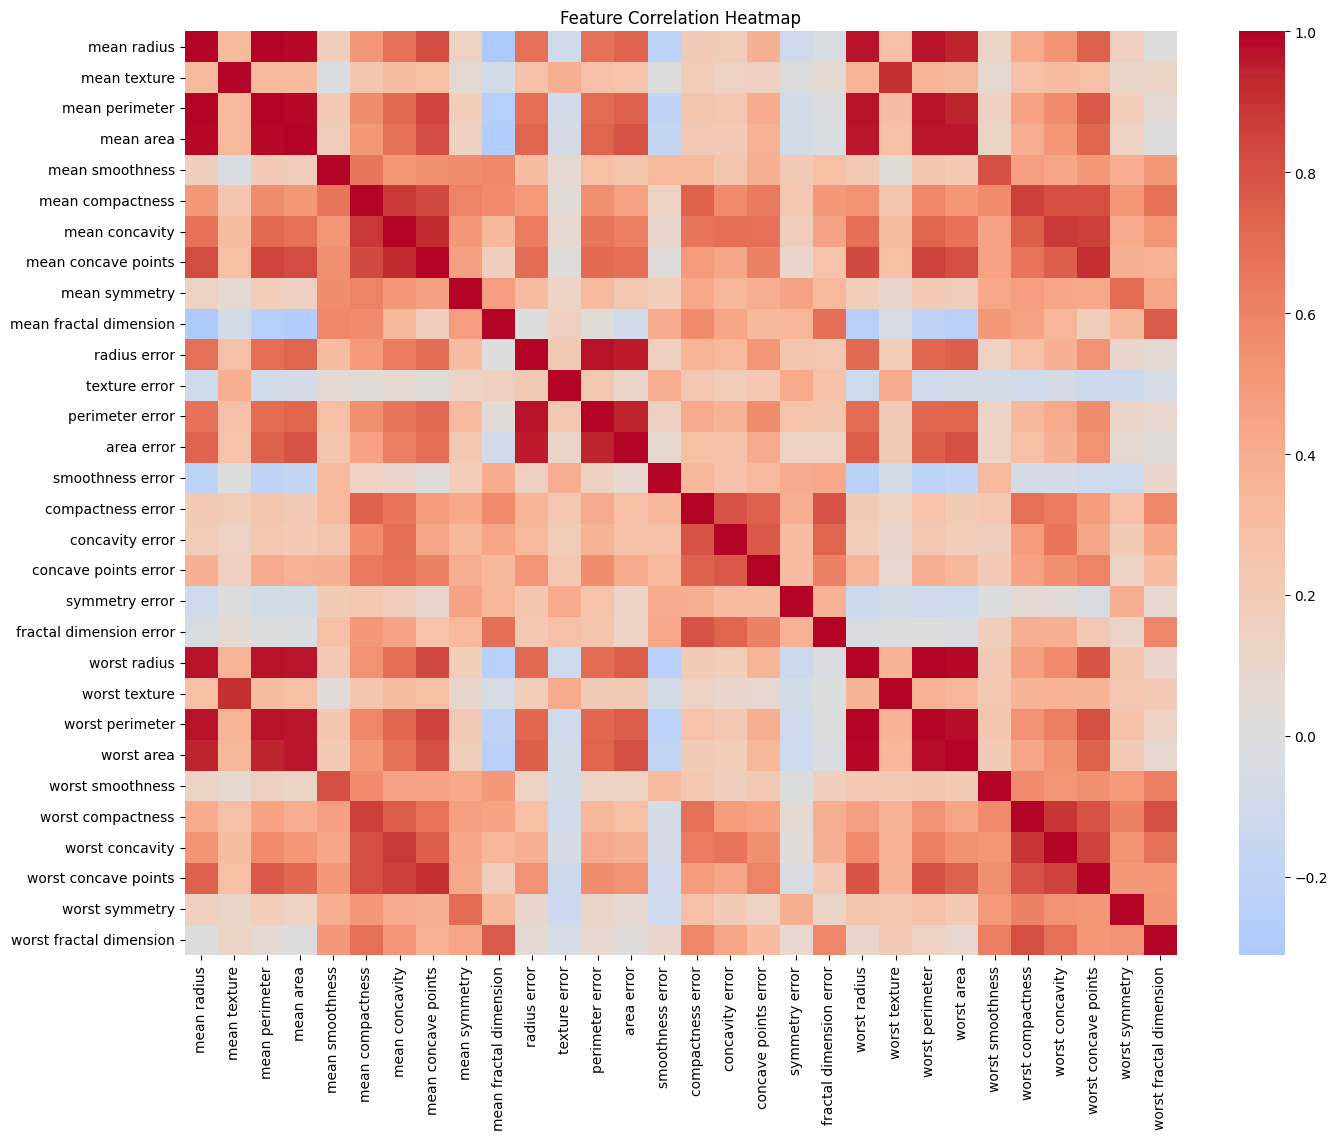

In [98]:
# Correlation Heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    df.drop(columns="target").corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

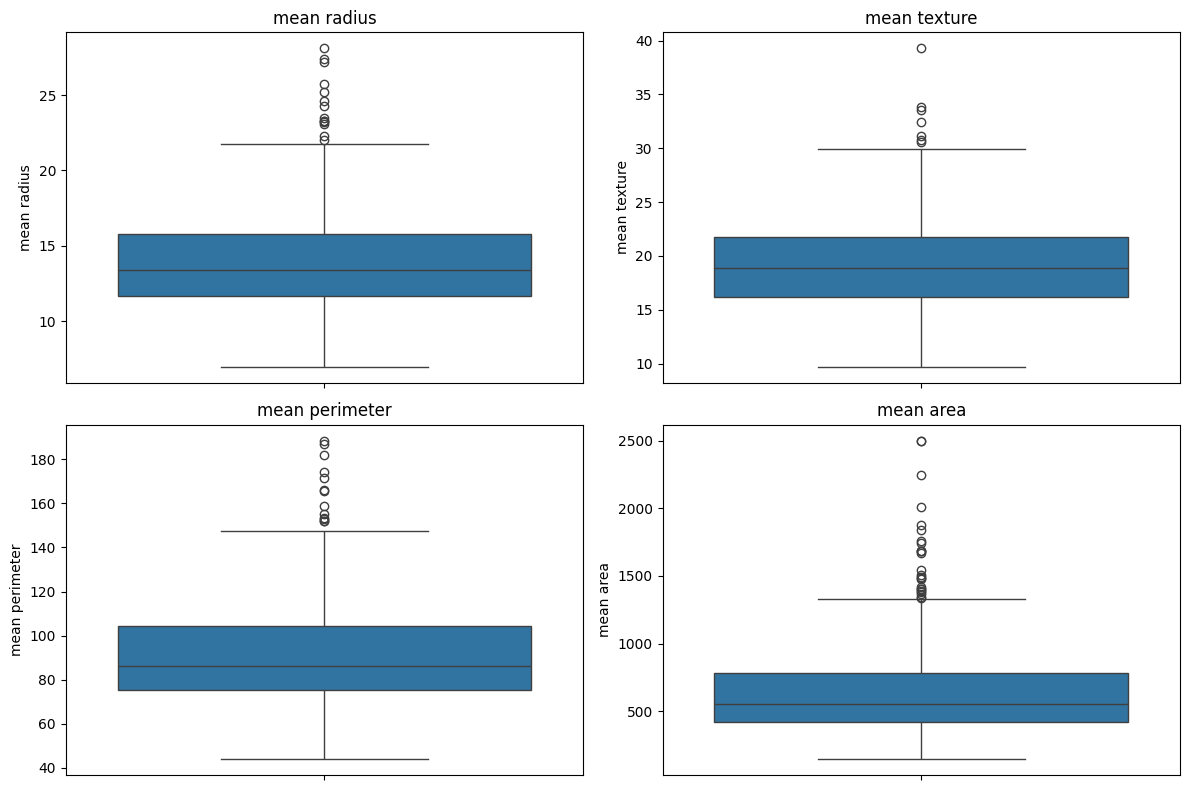

In [99]:
# Boxplots
selected_features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area"
]

plt.figure(figsize=(12, 8))

for i, feature in enumerate(selected_features, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=df, y=feature)
    plt.title(feature)

plt.tight_layout()
plt.show()

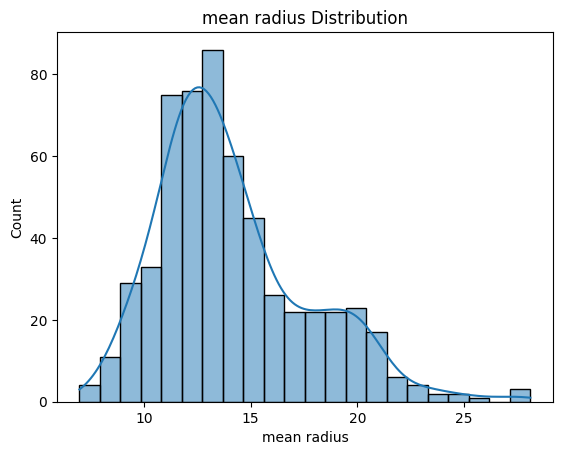

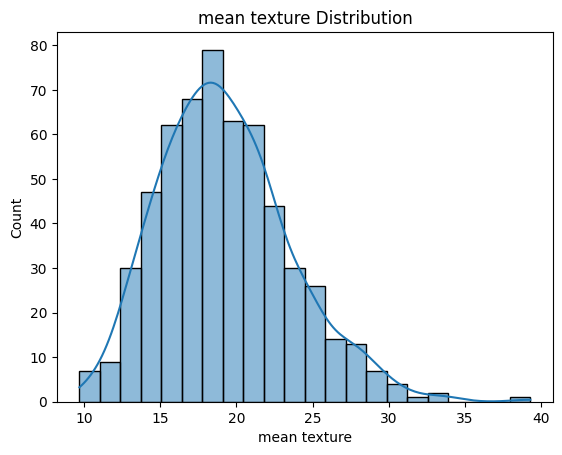

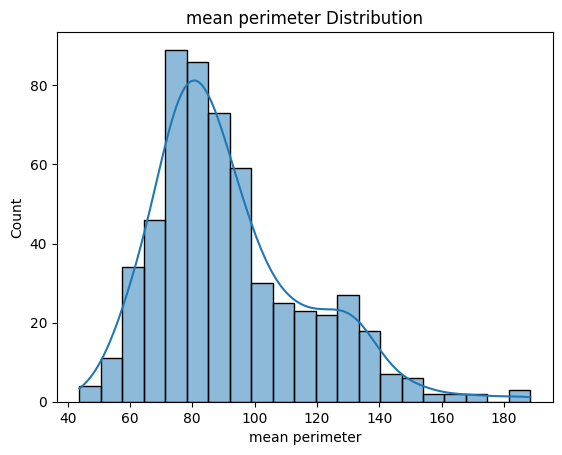

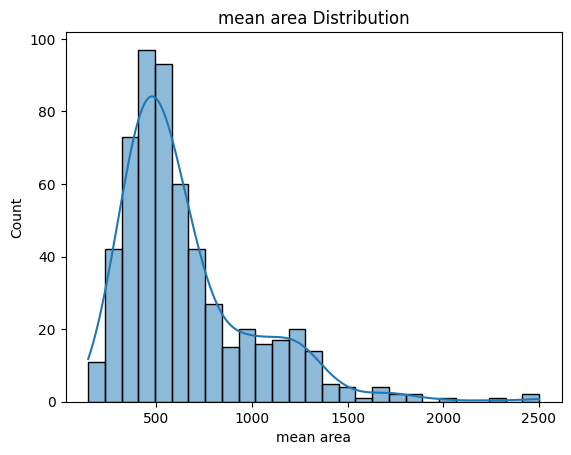

In [100]:
# Distribution Plots
for feature in selected_features:
    sns.histplot(data=df, x=feature, kde=True)
    plt.title(feature + " Distribution")
    plt.show()

### EDA Summary

1. **Class Balance:** The dataset is slightly imbalanced because there are more benign cases than malignant cases.

2. **Feature Correlation:** Some features are highly correlated, such as mean radius, mean perimeter, and mean area.

3. **Outliers:** Some numerical features contain visible outliers in the boxplots.

4. **Useful Features:** Features such as mean radius, mean perimeter, mean area, and worst concave points may be useful for classification.

##  Prepare the Features and Target

In [101]:
x = df.drop(columns="target")
y = df["target"]

In [102]:
x

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [103]:
y

,target
0,0
1,0
2,0
3,0
4,0
...,...
564,0
565,0
566,0
567,0


In [104]:
# Check for categorical features
print("Categorical features:", x.select_dtypes(include="object").columns)

Categorical features: Index([], dtype='object')


In [105]:
# No encoding is needed because all features are numerical

In [106]:
print("Outliers check:")
x.describe()

Outliers check:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [107]:
print("x shape:", x.shape)

x shape: (569, 30)


In [108]:
print("y shape:", y.shape)

y shape: (569,)


In [109]:
print("Target classes:", y.unique())

Target classes: [0 1]


## Train-Test Split

In [110]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [111]:
print("X_train shape:", x_train.shape)
print("X_test shape:", x_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (455, 30)
X_test shape: (114, 30)
y_train shape: (455,)
y_test shape: (114,)


## Scale the Data Without Data Leakage

In [112]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)

x_test_scaled = scaler.transform(x_test)

In [113]:
print("X_train_scaled shape:", x_train_scaled.shape)

X_train_scaled shape: (455, 30)


In [114]:
print("X_test_scaled shape:", x_test_scaled.shape)

X_test_scaled shape: (114, 30)


## Build the Baseline ANN Model

In [115]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

In [116]:
# Build the ANN model
model = Sequential([
    tf.keras.Input(shape=(30,)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

In [117]:
# Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [118]:
model.summary()

Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_57 (Dense)                │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_58 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

## Train the Baseline Model

In [119]:
from tensorflow.keras.callbacks import EarlyStopping

In [120]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)


In [121]:
# Train the model
history = model.fit(
    x_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7060 - loss: 0.5794 - val_accuracy: 0.7253 - val_loss: 0.5085
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7802 - loss: 0.5244 - val_accuracy: 0.8571 - val_loss: 0.4317
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8214 - loss: 0.4368 - val_accuracy: 0.9670 - val_loss: 0.3703
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8544 - loss: 0.3714 - val_accuracy: 0.9670 - val_loss: 0.3230
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8929 - loss: 0.3008 - val_accuracy: 0.9890 - val_loss: 0.2840
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8764 - loss: 0.2945 - val_accuracy: 0.9780 - val_loss: 0.2529
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8791 - loss: 0.2816 - val_accuracy: 0.9780 - val_loss: 0.2266
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9038 - loss: 0.2522 - val_accuracy: 0.9780 -

##  Evaluate the Baseline Model

In [122]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

In [123]:
train_loss, train_accuracy = model.evaluate(
    x_train_scaled, y_train, verbose=0
)

test_loss, test_accuracy = model.evaluate(
    x_test_scaled, y_test, verbose=0
)

print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

Training Accuracy: 0.9912087917327881
Test Accuracy: 0.9649122953414917


In [124]:
# Predict test labels
y_prob = model.predict(x_test_scaled, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).ravel()

In [125]:
# Calculate evaluation metrics
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))

Precision: 0.9857142857142858
Recall: 0.9583333333333334
F1-score: 0.971830985915493


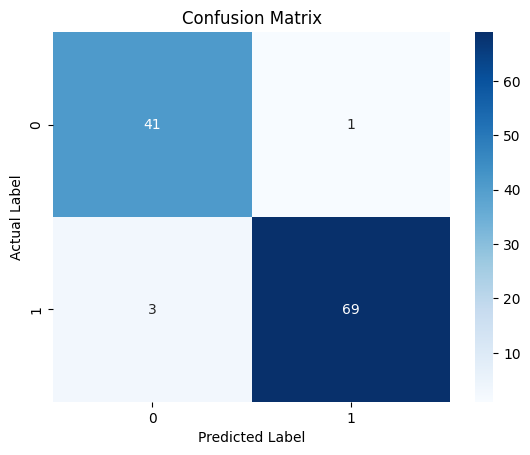

In [126]:
# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [127]:
# Display classification report
print(classification_report(
    y_test,
    y_pred,
    target_names=["Malignant", "Benign"]
))

              precision    recall  f1-score   support

   Malignant       0.93      0.98      0.95        42
      Benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



The model generalizes well because the training and test accuracy are high and close to each other, indicating good performance on unseen data.

## Improve the ANN Model

In [128]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam, RMSprop
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd


In [129]:
experiments = [
    ["Baseline", "relu", Adam(0.001), 16, 0.3, False],
    ["Tanh Activation", "tanh", Adam(0.001), 16, 0.3, False],
    ["RMSprop Optimizer", "relu", RMSprop(0.001), 16, 0.3, False],
    ["Low Learning Rate", "relu", Adam(0.0001), 16, 0.3, False],
    ["More Neurons", "relu", Adam(0.001), 32, 0.2, False],
    ["Batch Normalization", "relu", Adam(0.001), 32, 0.2, True]
]

baseline_history = history

results = []
trained_models = {}
histories = {}

In [130]:
for name, activation, optimizer, neurons, dropout, batch_norm in experiments:

    model_exp = Sequential([
        tf.keras.Input(shape=(30,)),
        Dense(neurons, activation=activation)
    ])

    if batch_norm:
        model_exp.add(BatchNormalization())

    model_exp.add(Dense(8, activation=activation))
    model_exp.add(Dropout(dropout))
    model_exp.add(Dense(1, activation="sigmoid"))

    model_exp.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    early_stop_exp = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )




In [131]:
history_exp = model_exp.fit(
    x_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop_exp],
    verbose=0
)


In [132]:
y_prob_exp = model_exp.predict(x_test_scaled, verbose=0)
y_pred_exp = (y_prob_exp >= 0.5).astype(int).ravel()

In [133]:
results.append({
    "Experiment": name,
    "Accuracy": accuracy_score(y_test, y_pred_exp),
    "Precision": precision_score(y_test, y_pred_exp, zero_division=0),
    "Recall": recall_score(y_test, y_pred_exp, zero_division=0),
    "F1-score": f1_score(y_test, y_pred_exp, zero_division=0)
})

trained_models[name] = model_exp
histories[name] = history_exp

In [134]:
results_df = pd.DataFrame(results)

print(results_df.round(4))

            Experiment  Accuracy  Precision  Recall  F1-score
0  Batch Normalization    0.9561     0.9855  0.9444    0.9645


In [135]:
# Select the best model
best_name = results_df.loc[
    results_df["F1-score"].idxmax(), "Experiment"
]

best_model = trained_models[best_name]
best_history = histories[best_name]

print("Best Model:", best_name)
print(results_df[results_df["Experiment"] == best_name])

Best Model: Batch Normalization
            Experiment  Accuracy  Precision    Recall  F1-score
0  Batch Normalization   0.95614   0.985507  0.944444  0.964539


## Visualize Training Result

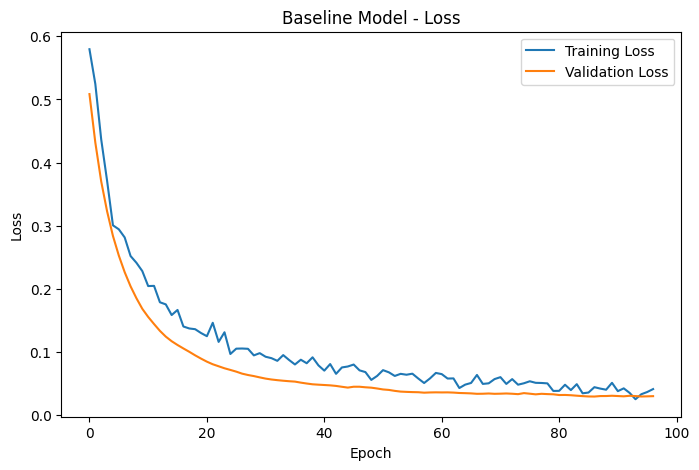

In [136]:
# Plot baseline loss
plt.figure(figsize=(8, 5))
plt.plot(baseline_history.history["loss"], label="Training Loss")
plt.plot(baseline_history.history["val_loss"], label="Validation Loss")

plt.title("Baseline Model - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

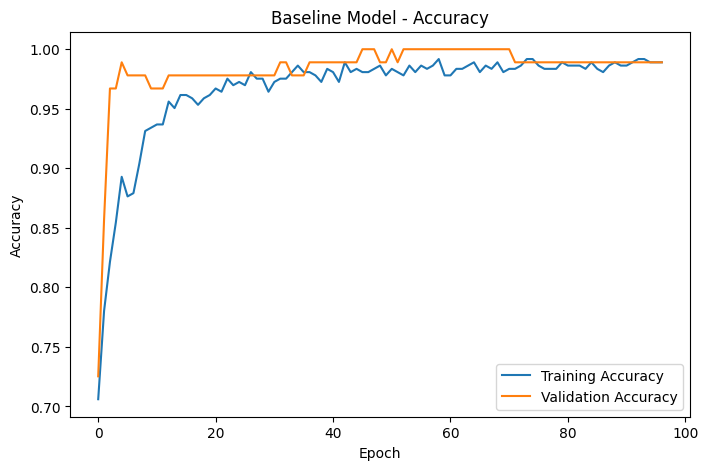

In [137]:
# Plot baseline accuracy
plt.figure(figsize=(8, 5))
plt.plot(baseline_history.history["accuracy"], label="Training Accuracy")
plt.plot(baseline_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Baseline Model - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

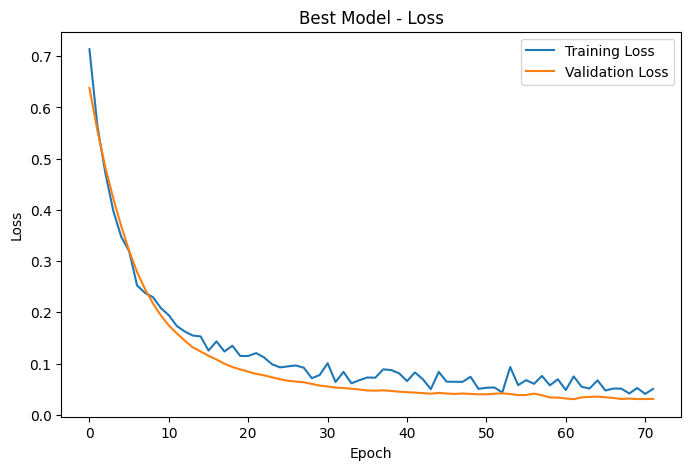

In [138]:
# Plot best model loss
plt.figure(figsize=(8, 5))
plt.plot(best_history.history["loss"], label="Training Loss")
plt.plot(best_history.history["val_loss"], label="Validation Loss")

plt.title("Best Model - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

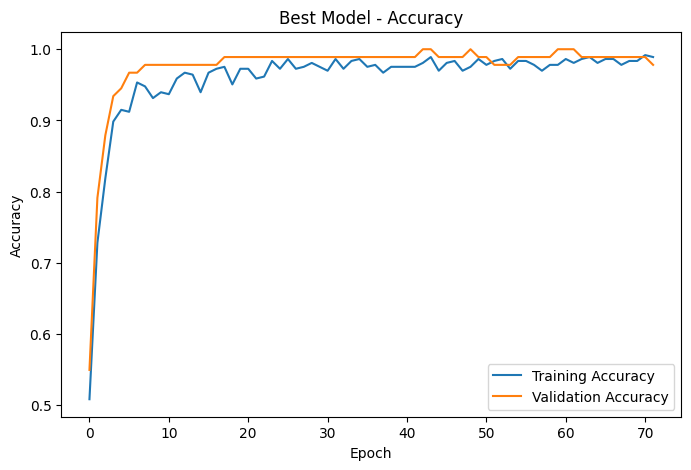

In [139]:
# Plot best model accuracy
plt.figure(figsize=(8, 5))
plt.plot(best_history.history["accuracy"], label="Training Accuracy")
plt.plot(best_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Best Model - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

The best model improved the classification performance compared
to the baseline model. The training and validation curves were
compared to check for overfitting. A small gap between the curves
indicates good generalization.